In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from os import listxattr
class TwoLayersPerceptron:

  # Inicializa el perceptrón
    def __init__(self, input_size, hidden_size, output_size, seed):

        # Inicializa el Perceptrón con una capa oculta

        # Parametros:
        # - input_size: Número de features de entrada
        # - hidden_size: Número de neuronas en la capa oculta
        # - output_size: Número de neuronas en la capa de salida
        # - seed: Semilla para el generador aleatorio

        # Vamos a utilizar una semilla para garantizar un comportamiento determinsita
        if seed is not None:
          np.random.seed(seed) # Si la semilla no es vacía, se establece como semilla

        # Establecemos los parámetros
        #self.input_size = input_size
        #self.hidden_size = hidden_size
        #self.output_size = output_size


        # Inicializacion de los pesos y sesgos
        self.W1 = np.random.randn(input_size, hidden_size)    # Input to hidden
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size)   # Hidden to output
        self.b2 = np.zeros((1, output_size))

    # Función de activación para la capa oculta
    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    # Derivada de la función sigmoide
    def _sigmoid_deriv(self, x):
        return x * (1 - x)

    # Realiza la prediccion para un conjunto de datos X que pasa como entrada
    def predict(self, X):
        z1 = np.dot(X, self.W1) + self.b1
        a1 = self._sigmoid(z1)
        z2 = np.dot(a1, self.W2) + self.b2
        # la salida es lineal para problemas de regresión
        output = z2
        return output

    # Entrena el modelo
    def fit(self, X, y, learning_rate=0.01, epochs=100):

        history_error = []

        for epoch in range(epochs):
            # Forward pass
            z1 = np.dot(X, self.W1) + self.b1
            a1 = self._sigmoid(z1)
            z2 = np.dot(a1, self.W2) + self.b2
            output = z2

            # Backward pass
            error = y - output
            # Calculamos el MSE = Error cuadratico medio
            mse = np.mean(error**2)
            history_error.append(mse) # lo guardamos en la lista para terner control

            d_output = error
            error_hidden = d_output.dot(self.W2.T)
            d_hidden = error_hidden * self._sigmoid_deriv(a1)

            # Update weights and biases
            self.W2 += a1.T.dot(d_output) * learning_rate
            self.b2 += np.sum(d_output, axis=0, keepdims=True) * learning_rate
            self.W1 += X.T.dot(d_hidden) * learning_rate
            self.b1 += np.sum(d_hidden, axis=0, keepdims=True) * learning_rate

            # mostramos el proceso
            if (epoch + 1) % (epochs // 10 if epochs >= 10 else 1) == 0:
                print(f"Época {epoch + 1}/{epochs} - MSE: {mse:.6f}")

        return history_error



--- Iniciando Entrenamiento ---
Época 3500/35000 - MSE: 0.003877
Época 7000/35000 - MSE: 0.001786
Época 10500/35000 - MSE: 0.000874
Época 14000/35000 - MSE: 0.000478
Época 17500/35000 - MSE: 0.000309
Época 21000/35000 - MSE: 0.000236
Época 24500/35000 - MSE: 0.000204
Época 28000/35000 - MSE: 0.000190
Época 31500/35000 - MSE: 0.000182
Época 35000/35000 - MSE: 0.000178

Primeras 5 predicciones vs valores reales:
Predicción: -0.0249 | Real: -0.0001
Predicción: -0.0175 | Real: -0.0001
Predicción: -0.0108 | Real: -0.0002
Predicción: -0.0047 | Real: -0.0003
Predicción: 0.0007 | Real: -0.0004


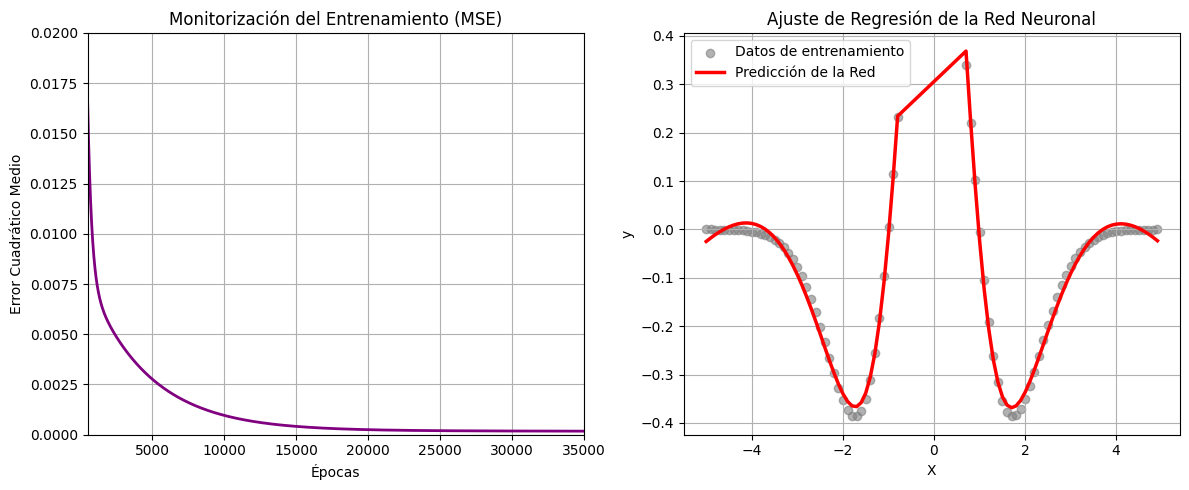

In [27]:

# GENERACION Y CARGA DE DATOS DEL ENTRENAMIENTO

data = np.loadtxt('/data_train.csv', delimiter=',', skiprows=1)
# como no se podia usar librerias, he convertido el .parquet en .cvs
X_train = data[:, :-1]
y_train = data[:, -1:]

#print("Conjunto X:", X_train)
#print("Conjunto Y:", y_train)


np.random.seed(42)


# ENTRENAMIENTO

input_dim = X_train.shape[1]
hidden_dim = 100     # Neuronas en la capa oculta (suficientes para aproximar funciones no lineales)
output_dim = y_train.shape[1]
seed_value = 42     # Semilla fija para reproducibilidad exacta

modelo = TwoLayersPerceptron(
    input_size=input_dim,
    hidden_size=hidden_dim,
    output_size=output_dim,
    seed=seed_value
)

print("--- Iniciando Entrenamiento ---")
historial_error = modelo.fit(
    X_train, y_train,
    learning_rate=0.001,
    epochs=35000
)

predictions = modelo.predict(X_train)
print("\nPrimeras 5 predicciones vs valores reales:")
for i in range(5):
    print(F"Predicción: {predictions[i][0]:.4f} | Real: {y_train[i][0]:.4f}")


# MONITORIZACION

plt.figure(figsize=(12, 5))

# Gráfica 1: Evolución del Error (MSE)
plt.subplot(1, 2, 1)
plt.plot(historial_error, color='purple', lw=2)
plt.title('Monitorización del Entrenamiento (MSE)')
plt.xlabel('Épocas')
plt.ylabel('Error Cuadrático Medio')
plt.axis([500, len(historial_error), 0, 0.02])
plt.grid(True)

# Gráfica 2: Ajuste del Modelo vs Datos Reales
y_pred = modelo.predict(X_train)
plt.subplot(1, 2, 2)
plt.scatter(X_train, y_train, color='gray', label='Datos de entrenamiento', alpha=0.6)
plt.plot(X_train, y_pred, color='red', lw=2.5, label='Predicción de la Red')
plt.title('Ajuste de Regresión de la Red Neuronal')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
